# POYO on ec013 2D (torch_brain version)

Notes:
- sessions: ec013.248 and ec013.250 (open square)
- target: 2D position
- continuous data is windowed into equal-length pseudo-trials
- visualization is inline (whole 2D trajectory + partial neural snippets)


In [1]:
from pathlib import Path
import sys
import pickle
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch.utils.data import Dataset as TorchDataset, DataLoader
from sklearn.metrics import r2_score, mean_squared_error

repo_root = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "foundation" / "torch_brain").exists()), None)
if repo_root is None:
    raise FileNotFoundError("Could not locate repo root containing foundation/torch_brain")

tb_root = repo_root / "foundation" / "torch_brain"
if str(tb_root) not in sys.path:
    sys.path.insert(0, str(tb_root))

from torch_brain.models import POYO
from torch_brain.registry import MODALITY_REGISTRY
from torch_brain.utils import create_linspace_latent_tokens

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("repo_root:", repo_root)
print("torch_brain root:", tb_root)
print("device:", device)



def flatten_spike_raw(spike_raw, fs_spike, session_id):
    unit_names = []
    unit_timestamps = []
    scale = float(fs_spike) if np.isfinite(fs_spike) else 20000.0
    for tetrode in sorted(spike_raw.keys(), key=lambda k: int(k)):
        units = spike_raw[tetrode]
        for unit_id in sorted(units.keys()):
            arr = np.asarray(units[unit_id], dtype=np.float64)
            timestamps = arr / scale
            unit_names.append(f"{session_id}|T{tetrode}.U{unit_id}")
            unit_timestamps.append(timestamps)
    return unit_names, unit_timestamps


repo_root: D:\comets
torch_brain root: D:\comets\foundation\torch_brain
device: cuda


In [2]:
crcns_root = repo_root / "data" / "crcns_mouse"
sessions = ["ec013.248", "ec013.250"]
session_data = {}

for sid in sessions:
    p = crcns_root / sid / f"{sid}_lfp_spike.pkl"
    if not p.exists():
        raise FileNotFoundError(p)
    with p.open("rb") as f:
        d = pickle.load(f)
    session_data[sid] = d
    pos2d = np.asarray(d.get("position_2d", d["position"]))
    if pos2d.ndim == 1:
        pos2d = np.column_stack([pos2d, np.zeros_like(pos2d)])
    fs = int(d["fs_common"])
    n_bins = pos2d.shape[0]
    duration = n_bins / fs
    spike_bin = np.asarray(d["spike_bin"])
    n_units = spike_bin.shape[1]
    total_spikes = int(spike_bin.sum())
    tetrodes = sorted(d["spike_raw"].keys(), key=lambda v: int(v))
    raw_units = sum(len(d["spike_raw"][t]) for t in tetrodes)
    print("")
    print(f"=== {sid} ===")
    print(f"  track_mode: {d.get('track_mode', 'unknown')}, fs_common: {fs} Hz")
    print(f"  bins: {n_bins} ({duration:.1f} s), units: {n_units} (raw {raw_units}), tetrodes: {len(tetrodes)}")
    print(f"  position_2d shape: {pos2d.shape}, spike_bin shape: {spike_bin.shape}")



=== ec013.248 ===
  track_mode: 2d, fs_common: 50 Hz
  bins: 91791 (1835.8 s), units: 73 (raw 73), tetrodes: 8
  position_2d shape: (91791, 2), spike_bin shape: (91791, 73)

=== ec013.250 ===
  track_mode: 2d, fs_common: 50 Hz
  bins: 92631 (1852.6 s), units: 65 (raw 65), tetrodes: 8
  position_2d shape: (92631, 2), spike_bin shape: (92631, 65)


## Visualization (inline)


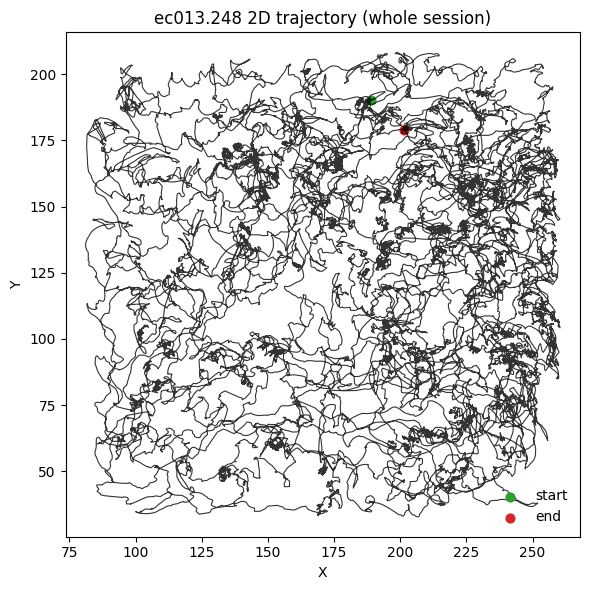

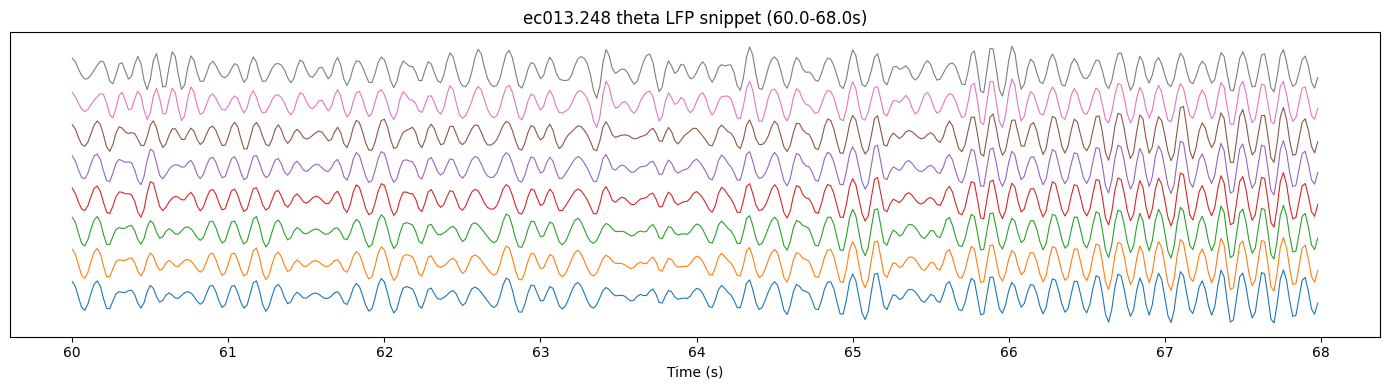

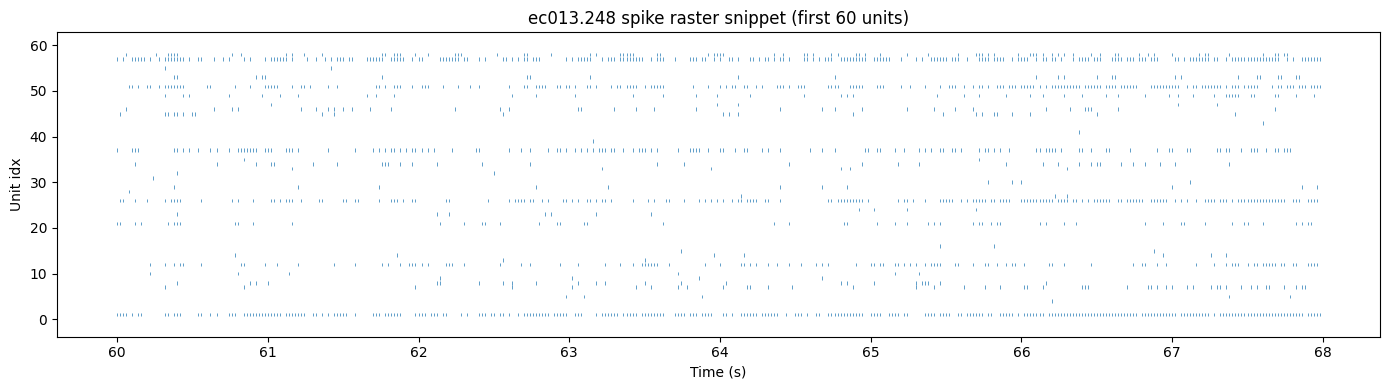

In [3]:
sid = "ec013.248"
d = session_data[sid]

fs = int(d["fs_common"])
pos2d = np.asarray(d.get("position_2d", d["position"]))
if pos2d.ndim == 1:
    pos2d = np.column_stack([pos2d, np.zeros_like(pos2d)])
spk = np.asarray(d["spike_bin"])
lfp = np.asarray(d["lfp_theta"])

T = min(len(pos2d), len(spk), len(lfp))
pos2d = pos2d[:T]
spk = spk[:T]
lfp = lfp[:T]

plt.figure(figsize=(6, 6))
plt.plot(pos2d[:, 0], pos2d[:, 1], color="black", lw=0.8, alpha=0.8)
plt.scatter(pos2d[0, 0], pos2d[0, 1], c="tab:green", s=40, label="start")
plt.scatter(pos2d[-1, 0], pos2d[-1, 1], c="tab:red", s=40, label="end")
plt.title(f"{sid} 2D trajectory (whole session)")
plt.xlabel("X")
plt.ylabel("Y")
plt.legend(frameon=False)
plt.axis("equal")
plt.tight_layout()
plt.show()

t0_s = 60.0
dur_s = 8.0
i0 = int(t0_s * fs)
i1 = min(T, int((t0_s + dur_s) * fs))
t = np.arange(i0, i1) / fs

rng = np.random.default_rng(0)
ch = np.sort(rng.choice(lfp.shape[1], size=min(8, lfp.shape[1]), replace=False))
lfp_seg = lfp[i0:i1, :][:, ch]
lfp_seg = (lfp_seg - lfp_seg.mean(0, keepdims=True)) / (lfp_seg.std(0, keepdims=True) + 1e-9)
plt.figure(figsize=(14, 4))
for i in range(lfp_seg.shape[1]):
    plt.plot(t, lfp_seg[:, i] + 3.0 * i, lw=0.8)
plt.title(f"{sid} theta LFP snippet ({t0_s:.1f}-{t0_s+dur_s:.1f}s)")
plt.xlabel("Time (s)")
plt.yticks([])
plt.tight_layout()
plt.show()

n_units = min(60, spk.shape[1])
events = [np.where(spk[i0:i1, u] > 0)[0] / fs + t0_s for u in range(n_units)]
plt.figure(figsize=(14, 4))
plt.eventplot(events, lineoffsets=np.arange(n_units), linelengths=0.8, linewidths=0.5)
plt.title(f"{sid} spike raster snippet (first {n_units} units)")
plt.xlabel("Time (s)")
plt.ylabel("Unit idx")
plt.tight_layout()
plt.show()


## Continuous -> equal-length windows (pseudo-trials)
This is the fix for continuous data: cut each session into fixed windows and train on those windows.


In [4]:
window_sec = 1.0
stride_sec = 0.25

session_arrays = {}
window_records = []
split_fracs = (0.7, 0.15, 0.15)

for sid in sessions:
    d = session_data[sid]
    fs = float(d["fs_common"])
    pos2d = np.asarray(d.get("position_2d", d["position"]))
    if pos2d.ndim == 1:
        pos2d = np.column_stack([pos2d, np.zeros_like(pos2d)])
    T = pos2d.shape[0]
    duration = float(T) / fs

    spike_raw = d["spike_raw"]
    fs_spike = 20000
    unit_names, unit_timestamps = flatten_spike_raw(spike_raw, fs_spike, sid)
    total_spikes = sum(unit.shape[0] for unit in unit_timestamps)

    session_arrays[sid] = {
        "fs": fs,
        "pos2d": pos2d.astype(np.float32),
        "duration": duration,
        "unit_names": unit_names,
        "unit_timestamps": unit_timestamps,
        "fs_spike": fs_spike,
    }

    win_bins = int(round(window_sec * fs))
    stride_bins = max(1, int(round(stride_sec * fs)))
    starts = np.arange(0, max(0, T - win_bins + 1), stride_bins, dtype=np.int64)

    valid_starts = []
    for start in starts:
        window_slice = pos2d[start : start + win_bins]
        if not np.isfinite(window_slice).all():
            continue
        valid_starts.append(int(start))

    if not valid_starts:
        raise RuntimeError(f"No valid windows found for {sid}")

    n = len(valid_starts)
    n_train = int(split_fracs[0] * n)
    n_val = int(split_fracs[1] * n)

    for idx, start in enumerate(valid_starts):
        if idx < n_train:
            split = "train"
        elif idx < n_train + n_val:
            split = "val"
        else:
            split = "test"
        window_records.append((sid, start, split))

    print(f"{sid}: duration {duration:.1f}s, {len(unit_names)} units, {total_spikes} spikes, windows {n}")

print("total windows:", len(window_records))
print("train:", sum(1 for r in window_records if r[2] == "train"))
print("val:", sum(1 for r in window_records if r[2] == "val"))
print("test:", sum(1 for r in window_records if r[2] == "test"))


ec013.248: duration 1835.8s, 73 units, 750710 spikes, windows 7646
ec013.250: duration 1852.6s, 65 units, 802348 spikes, windows 7716
total windows: 15362
train: 10753
val: 2303
test: 2306


In [5]:
global_unit_names = []
global_unit_map = {}

for sid in sessions:
    names = session_arrays[sid]["unit_names"]
    start = len(global_unit_names)
    global_unit_names.extend(names)
    global_unit_map[sid] = np.arange(start, start + len(names), dtype=np.int64)

session_names = sessions.copy()
session_token_map = {sid: i for i, sid in enumerate(session_names)}

poyo = POYO(
    sequence_length=float(window_sec),
    readout_spec=MODALITY_REGISTRY["cursor_position_2d"],
    latent_step=0.125,
    num_latents_per_step=16,
    dim=128,
    depth=2,
    dim_head=32,
    cross_heads=1,
    self_heads=4,
    ffn_dropout=0.0,
    lin_dropout=0.0,
    atn_dropout=0.0,
).to(device)

poyo.unit_emb.initialize_vocab(global_unit_names)
poyo.session_emb.initialize_vocab(session_names)

global_unit_ids = np.array(poyo.unit_emb.tokenizer(global_unit_names), dtype=np.int64)
for sid in sessions:
    local_placeholders = global_unit_map[sid]
    global_unit_map[sid] = global_unit_ids[local_placeholders]

session_token_map = {sid: int(poyo.session_emb.tokenizer(sid)) for sid in sessions}

latent_index_np, latent_timestamps_np = create_linspace_latent_tokens(
    0.0, float(window_sec), step=float(poyo.latent_step), num_latents_per_step=int(poyo.num_latents_per_step)
)
latent_index_t = torch.tensor(latent_index_np, dtype=torch.long)
latent_timestamps_t = torch.tensor(latent_timestamps_np, dtype=torch.float32)

print("global units:", len(global_unit_names))
print("session tokens:", session_token_map)


global units: 138
session tokens: {'ec013.248': 1, 'ec013.250': 2}


In [6]:
class EC013PoyoDataset2D(TorchDataset):
    def __init__(self, records, split, session_arrays, global_unit_map, session_token_map, win_sec, latent_index_t, latent_timestamps_t):
        self.records = [(sid, start) for (sid, start, sp) in records if sp == split]
        self.session_arrays = session_arrays
        self.global_unit_map = global_unit_map
        self.session_token_map = session_token_map
        self.win_sec = float(win_sec)
        self.latent_index_t = latent_index_t
        self.latent_timestamps_t = latent_timestamps_t

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        sid, start_bin = self.records[idx]
        arr = self.session_arrays[sid]
        fs = arr["fs"]
        pos2d = arr["pos2d"]
        win_bins = int(round(self.win_sec * fs))
        end_bin = start_bin + win_bins
        t0 = start_bin / fs

        unit_timestamps = arr["unit_timestamps"]
        global_ids = self.global_unit_map[sid]

        input_unit_chunks = []
        input_time_chunks = []

        for local_idx, timestamps in enumerate(unit_timestamps):
            if timestamps.size == 0:
                continue
            left = np.searchsorted(timestamps, t0, side="left")
            right = np.searchsorted(timestamps, t0 + self.win_sec, side="left")
            snippet = timestamps[left:right]
            if snippet.size == 0:
                continue
            input_unit_chunks.append(np.full(snippet.shape, global_ids[local_idx], dtype=np.int64))
            input_time_chunks.append(snippet - t0)

        if input_unit_chunks:
            input_unit_index = torch.tensor(np.concatenate(input_unit_chunks), dtype=torch.long)
            input_timestamps = torch.tensor(np.concatenate(input_time_chunks), dtype=torch.float32)
            input_token_type = torch.zeros(input_unit_index.shape[0], dtype=torch.long)
            input_mask = torch.ones(input_unit_index.shape[0], dtype=torch.bool)
        else:
            input_unit_index = torch.tensor([0], dtype=torch.long)
            input_timestamps = torch.tensor([0.0], dtype=torch.float32)
            input_token_type = torch.tensor([0], dtype=torch.long)
            input_mask = torch.tensor([False], dtype=torch.bool)

        out_timestamps = torch.arange(win_bins, dtype=torch.float32) / fs
        output_session_index = torch.full((win_bins,), self.session_token_map[sid], dtype=torch.long)
        output_mask = torch.ones(win_bins, dtype=torch.bool)
        target_values = torch.tensor(pos2d[start_bin:end_bin], dtype=torch.float32)

        return {
            "model_inputs": {
                "input_unit_index": input_unit_index,
                "input_timestamps": input_timestamps,
                "input_token_type": input_token_type,
                "input_mask": input_mask,
                "latent_index": self.latent_index_t.clone(),
                "latent_timestamps": self.latent_timestamps_t.clone(),
                "output_session_index": output_session_index,
                "output_timestamps": out_timestamps,
                "output_mask": output_mask,
            },
            "target_values": target_values,
        }

def ec013_2d_collate(batch):
    from torch.nn.utils.rnn import pad_sequence
    keys = ["input_unit_index", "input_timestamps", "input_token_type", "input_mask"]
    padded = {}
    for k in keys:
        vals = [b["model_inputs"][k] for b in batch]
        if k in ["input_unit_index", "input_token_type"]:
            padded[k] = pad_sequence(vals, batch_first=True, padding_value=0)
        elif k == "input_timestamps":
            padded[k] = pad_sequence(vals, batch_first=True, padding_value=0.0)
        else:
            padded[k] = pad_sequence(vals, batch_first=True, padding_value=False)

    model_inputs = {
        **padded,
        "latent_index": torch.stack([b["model_inputs"]["latent_index"] for b in batch], dim=0),
        "latent_timestamps": torch.stack([b["model_inputs"]["latent_timestamps"] for b in batch], dim=0),
        "output_session_index": torch.stack([b["model_inputs"]["output_session_index"] for b in batch], dim=0),
        "output_timestamps": torch.stack([b["model_inputs"]["output_timestamps"] for b in batch], dim=0),
        "output_mask": torch.stack([b["model_inputs"]["output_mask"] for b in batch], dim=0),
    }
    target_values = torch.stack([b["target_values"] for b in batch], dim=0)
    return {"model_inputs": model_inputs, "target_values": target_values}

def move_to_device(x, device):
    if isinstance(x, torch.Tensor):
        return x.to(device)
    if isinstance(x, dict):
        return {k: move_to_device(v, device) for k, v in x.items()}
    return x

train_ds = EC013PoyoDataset2D(window_records, "train", session_arrays, global_unit_map, session_token_map, window_sec, latent_index_t, latent_timestamps_t)
val_ds = EC013PoyoDataset2D(window_records, "val", session_arrays, global_unit_map, session_token_map, window_sec, latent_index_t, latent_timestamps_t)
test_ds = EC013PoyoDataset2D(window_records, "test", session_arrays, global_unit_map, session_token_map, window_sec, latent_index_t, latent_timestamps_t)

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=0, collate_fn=ec013_2d_collate)
val_loader = DataLoader(val_ds, batch_size=16, shuffle=False, num_workers=0, collate_fn=ec013_2d_collate)
test_loader = DataLoader(test_ds, batch_size=16, shuffle=False, num_workers=0, collate_fn=ec013_2d_collate)
print("windows -> train:", len(train_ds), "val:", len(val_ds), "test:", len(test_ds))


windows -> train: 10753 val: 2303 test: 2306


In [7]:
def masked_mse(pred, target, mask):
    m = mask.unsqueeze(-1).float()
    denom = torch.clamp(m.sum(), min=1.0)
    return (((pred - target) ** 2) * m).sum() / denom

opt = torch.optim.AdamW(poyo.parameters(), lr=1e-3, weight_decay=1e-4)
epochs = 10
train_loss_hist, val_loss_hist = [], []

for ep in range(1, epochs + 1):
    poyo.train()
    tr_sum, tr_steps = 0.0, 0
    for batch in train_loader:
        batch = move_to_device(batch, device)
        pred = poyo(**batch["model_inputs"])
        loss = masked_mse(pred, batch["target_values"], batch["model_inputs"]["output_mask"])
        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(poyo.parameters(), 1.0)
        opt.step()
        tr_sum += float(loss.item()); tr_steps += 1

    poyo.eval()
    va_sum, va_steps = 0.0, 0
    with torch.no_grad():
        for batch in val_loader:
            batch = move_to_device(batch, device)
            pred = poyo(**batch["model_inputs"])
            loss = masked_mse(pred, batch["target_values"], batch["model_inputs"]["output_mask"])
            va_sum += float(loss.item()); va_steps += 1

    tr = tr_sum / max(1, tr_steps)
    va = va_sum / max(1, va_steps)
    train_loss_hist.append(tr)
    val_loss_hist.append(va)
    print(f"epoch {ep:02d} train={tr:.5f} val={va:.5f}")


epoch 01 train=6006.13403 val=5033.43294
epoch 02 train=4732.36492 val=5182.33106
epoch 03 train=4629.89802 val=5349.39497
epoch 04 train=4598.55162 val=4937.50670
epoch 05 train=4647.11586 val=5012.23172
epoch 06 train=4581.99595 val=5042.17493
epoch 07 train=4564.60040 val=5093.80792
epoch 08 train=4528.67286 val=5149.69902
epoch 09 train=4536.22493 val=4871.79089
epoch 10 train=4538.13001 val=4957.78658


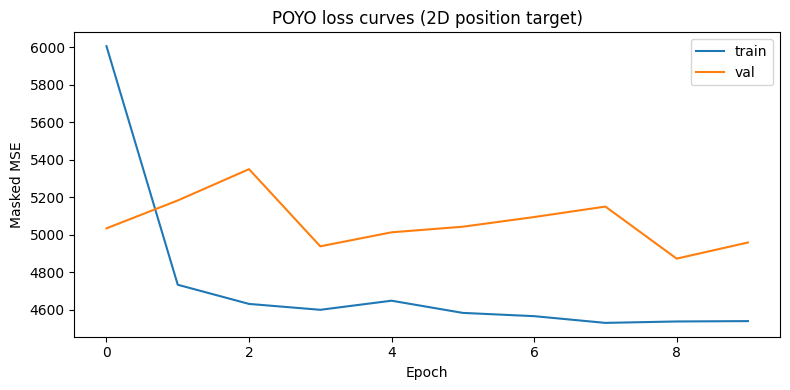

In [8]:
plt.figure(figsize=(8, 4))
plt.plot(train_loss_hist, label="train")
plt.plot(val_loss_hist, label="val")
plt.title("POYO loss curves (2D position target)")
plt.xlabel("Epoch")
plt.ylabel("Masked MSE")
plt.legend()
plt.tight_layout()
plt.show()


Test R2: 0.0904
Test RMSE: 41.3420
Unique test bins after overlap resolution: 27748


c:\Users\User\.conda\envs\torch_brain\Lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


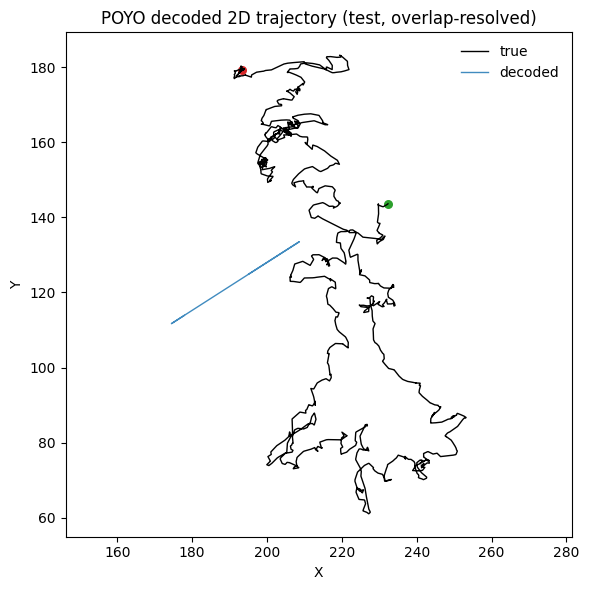

In [9]:
# Resolve overlap only for final test trajectory metrics/plot by averaging per global bin.
pred_sum, tgt_sum, count = {}, {}, {}
test_record_idx = 0

poyo.eval()
with torch.no_grad():
    for batch in test_loader:
        batch = move_to_device(batch, device)
        pred = poyo(**batch["model_inputs"]).detach().cpu()
        tgt = batch["target_values"].detach().cpu()
        mask = batch["model_inputs"]["output_mask"].detach().cpu()

        batch_size = pred.shape[0]
        batch_records = test_ds.records[test_record_idx : test_record_idx + batch_size]
        test_record_idx += batch_size

        for b, (sid, start_bin) in enumerate(batch_records):
            valid_idx = torch.nonzero(mask[b], as_tuple=False).squeeze(-1).numpy()
            if valid_idx.size == 0:
                continue

            pred_vals = pred[b, valid_idx, :].numpy()
            tgt_vals = tgt[b, valid_idx, :].numpy()

            for i_local, t_bin in enumerate(valid_idx):
                key = (sid, int(start_bin + int(t_bin)))
                if key not in pred_sum:
                    pred_sum[key] = np.zeros(pred_vals.shape[1], dtype=np.float64)
                    tgt_sum[key] = np.zeros(tgt_vals.shape[1], dtype=np.float64)
                    count[key] = 0
                pred_sum[key] += pred_vals[i_local]
                tgt_sum[key] += tgt_vals[i_local]
                count[key] += 1

if test_record_idx != len(test_ds.records):
    raise RuntimeError("test_ds.records and test_loader iteration are misaligned")

sorted_keys = sorted(pred_sum.keys(), key=lambda x: (x[0], x[1]))
y_pred = np.stack([pred_sum[k] / count[k] for k in sorted_keys], axis=0).astype(np.float32)
y_true = np.stack([tgt_sum[k] / count[k] for k in sorted_keys], axis=0).astype(np.float32)

r2 = r2_score(y_true, y_pred)
rmse = mean_squared_error(y_true, y_pred, squared=False)
print(f"Test R2: {r2:.4f}")
print(f"Test RMSE: {rmse:.4f}")
print(f"Unique test bins after overlap resolution: {len(sorted_keys)}")

nshow = min(3000, len(y_true))
plt.figure(figsize=(6, 6))
plt.plot(y_true[:nshow, 0], y_true[:nshow, 1], color="black", lw=1.0, label="true")
plt.plot(y_pred[:nshow, 0], y_pred[:nshow, 1], color="tab:blue", lw=1.0, alpha=0.85, label="decoded")
plt.scatter(y_true[0, 0], y_true[0, 1], c="tab:green", s=30)
plt.scatter(y_true[nshow - 1, 0], y_true[nshow - 1, 1], c="tab:red", s=30)
plt.title("POYO decoded 2D trajectory (test, overlap-resolved)")
plt.xlabel("X")
plt.ylabel("Y")
plt.legend(frameon=False)
plt.axis("equal")
plt.tight_layout()
plt.show()

## Training-window decoding
Inspect how POYO behaves on the training windows to spot overfit trends.


In [10]:
def gather_masked_predictions(loader, model, device, max_batches=6):
    preds, tgts, masks = [], [], []
    model.eval()
    with torch.no_grad():
        for idx, batch in enumerate(loader):
            if idx >= max_batches:
                break
            batch = move_to_device(batch, device)
            pred = poyo(**batch["model_inputs"])
            preds.append(pred.detach().cpu())
            tgts.append(batch["target_values"].detach().cpu())
            masks.append(batch["model_inputs"]["output_mask"].detach().cpu())
    if not preds:
        return torch.empty((0, model.readout.out_features)), torch.empty((0, model.readout.out_features))
    pred_flat = torch.cat([preds[i][b][masks[i][b]] for i in range(len(preds)) for b in range(preds[i].shape[0])], dim=0)
    tgt_flat = torch.cat([tgts[i][b][masks[i][b]] for i in range(len(tgts)) for b in range(tgts[i].shape[0])], dim=0)
    return pred_flat, tgt_flat


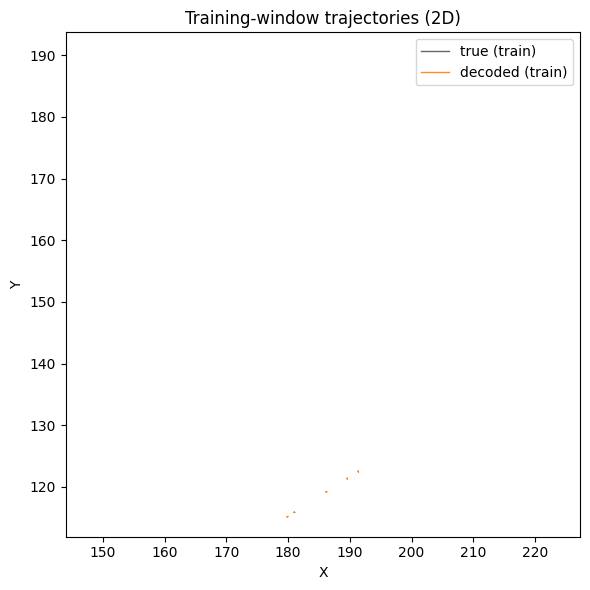

In [11]:
def collect_training_traces(loader, model, device, max_windows=6):
    traces = []
    model.eval()
    with torch.no_grad():
        for idx, batch in enumerate(loader):
            if idx >= max_windows:
                break
            batch = move_to_device(batch, device)
            pred = poyo(**batch["model_inputs"])
            mask = batch["model_inputs"]["output_mask"]
            if mask.shape[0] == 0:
                continue
            valid = mask[0]
            if valid.sum() == 0:
                continue
            traces.append((pred[0][valid].cpu(), batch["target_values"][0][valid].cpu()))
    return traces

train_vis_loader = DataLoader(train_ds, batch_size=1, shuffle=False, num_workers=0, collate_fn=ec013_2d_collate)
traces = collect_training_traces(train_vis_loader, poyo, device, max_windows=6)
if not traces:
    print("No training traces collected yet.")
else:
    plt.figure(figsize=(6, 6))
    for idx, (pred_win, true_win) in enumerate(traces):
        plt.plot(true_win[:, 0], true_win[:, 1], color="black", lw=1.0, alpha=0.6)
        plt.plot(pred_win[:, 0], pred_win[:, 1], color="tab:orange", lw=1.0, alpha=0.9)
    plt.title("Training-window trajectories (2D)")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.axis("equal")
    plt.tight_layout()
    plt.legend(["true (train)", "decoded (train)"])
    plt.show()


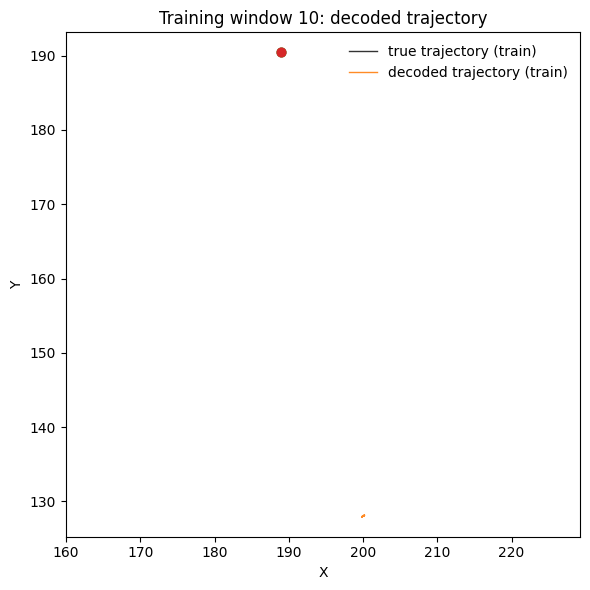

In [12]:
window_idx = 10
if window_idx >= len(train_ds):
    raise IndexError(f"window_idx {window_idx} out of range ({len(train_ds)})")
collated = ec013_2d_collate([train_ds[window_idx]])
batch = move_to_device(collated, device)
with torch.no_grad():
    pred = poyo(**batch['model_inputs'])
mask = batch['model_inputs']['output_mask'][0]
if mask.sum() == 0:
    raise RuntimeError('output_mask is empty for this window')
pred_window = pred[0][mask].detach().cpu().numpy()
true_window = batch['target_values'][0][mask].detach().cpu().numpy()
plt.figure(figsize=(6, 6))
plt.plot(true_window[:, 0], true_window[:, 1], color='black', lw=1.0, alpha=0.8, label='true trajectory (train)')
plt.plot(pred_window[:, 0], pred_window[:, 1], color='tab:orange', lw=1.0, alpha=0.9, label='decoded trajectory (train)')
plt.scatter(true_window[0, 0], true_window[0, 1], c='tab:green', s=40)
plt.scatter(true_window[-1, 0], true_window[-1, 1], c='tab:red', s=40)
plt.title(f'Training window {window_idx}: decoded trajectory')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend(frameon=False)
plt.axis('equal')
plt.tight_layout()
plt.show()
